In [12]:
import json
import random
from datetime import datetime, timedelta

data = []
start_date = datetime(2025, 1, 1)

for i in range(5000):

    treatment_cost = random.randint(5000, 30000)

    # Normal claim with some noise
    claim_amount = int(treatment_cost * random.uniform(0.9, 1.3))
    fraud_flag = 0

    # Introduce fraud in 15% of cases with some variation
    if random.random() < 0.15:
        # Fraud can be slightly less obvious sometimes
        claim_amount = int(treatment_cost * random.uniform(1.3, 2.5))
        # Randomly make some fraud claims close to normal to create realistic edge cases
        if random.random() < 0.2:
            claim_amount = int(treatment_cost * random.uniform(1.1, 1.4))
        fraud_flag = 1

    # Randomly introduce some normal claims that look suspicious
    if fraud_flag == 0 and random.random() < 0.05:
        claim_amount = int(treatment_cost * random.uniform(1.3, 1.6))

    record = {
        "claim_id": f"C{10000+i}",
        "patient_id": f"P{5000+i}",
        "hospital_id": f"H{random.randint(10,25)}",
        "doctor_id": f"D{random.randint(10,80)}",
        "treatment_code": f"T{random.randint(200,220)}",
        "treatment_cost": treatment_cost,
        "insurance_claim_amount": claim_amount,
        "claim_date": (start_date + timedelta(days=random.randint(0,365))).strftime("%Y-%m-%d"),
        "fraud_flag": fraud_flag
    }

    data.append(record)

# Save to JSON
with open("insurance_claim_dataset_realistic.json", "w") as f:
    json.dump(data, f, indent=4)

print("Realistic dataset with 5000 records generated")

Realistic dataset with 5000 records generated


In [13]:
import pandas as pd

# Load JSON file
df = pd.read_json("/kaggle/working/insurance_claim_dataset_realistic.json")

# Inspect first few rows
df.head()

,claim_id,patient_id,hospital_id,doctor_id,treatment_code,treatment_cost,insurance_claim_amount,claim_date,fraud_flag
0,C10000,P5000,H18,D55,T215,8537,13173,2025-03-20,0
1,C10001,P5001,H10,D36,T215,16864,18439,2025-07-15,0
2,C10002,P5002,H19,D12,T205,8594,9672,2025-07-21,0
3,C10003,P5003,H13,D32,T220,8971,10979,2025-01-05,0
4,C10004,P5004,H11,D43,T211,14660,18945,2025-01-28,1


In [14]:
df.info()
df['fraud_flag'].value_counts()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   claim_id                5000 non-null   object
 1   patient_id              5000 non-null   object
 2   hospital_id             5000 non-null   object
 3   doctor_id               5000 non-null   object
 4   treatment_code          5000 non-null   object
 5   treatment_cost          5000 non-null   int64 
 6   insurance_claim_amount  5000 non-null   int64 
 7   claim_date              5000 non-null   object
 8   fraud_flag              5000 non-null   int64 
dtypes: int64(3), object(6)
memory usage: 351.7+ KB


fraud_flag
0    4210
1     790
Name: count, dtype: int64

In [18]:
if 'claim_date' in df.columns:
    df['claim_date'] = pd.to_datetime(df['claim_date'])
    df['year'] = df['claim_date'].dt.year
    df['month'] = df['claim_date'].dt.month
    df['day'] = df['claim_date'].dt.day
    df = df.drop('claim_date', axis=1)

In [24]:
import pandas as pd

# Reload the JSON dataset
df = pd.read_json("/kaggle/working/insurance_claim_dataset_realistic.json")

# Now the claim_date column exists again

In [25]:
df['claim_ratio'] = (df['insurance_claim_amount'] / df['treatment_cost']).round(2)

df['claim_date'] = pd.to_datetime(df['claim_date'])
df['year'] = df['claim_date'].dt.year
df['month'] = df['claim_date'].dt.month
df['day'] = df['claim_date'].dt.day
df = df.drop(['claim_id','patient_id','claim_date'], axis=1)

In [27]:
# Step 1: Create claim_ratio
df['claim_ratio'] = (df['insurance_claim_amount'] / df['treatment_cost']).round(2)

# Step 2: Only process claim_date if it exists
if 'claim_date' in df.columns:
    df['claim_date'] = pd.to_datetime(df['claim_date'])
    df['year'] = df['claim_date'].dt.year
    df['month'] = df['claim_date'].dt.month
    df['day'] = df['claim_date'].dt.day
    df = df.drop('claim_date', axis=1)

# Step 3: Drop non-predictive columns
for col in ['claim_id','patient_id']:
    if col in df.columns:
        df = df.drop(col, axis=1)

# Step 4: Encode categorical features
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in ['hospital_id','doctor_id','treatment_code']:
    if col in df.columns:
        df[col] = le.fit_transform(df[col])

# Check final dataset
df.head()

,hospital_id,doctor_id,treatment_code,treatment_cost,insurance_claim_amount,fraud_flag,claim_ratio,year,month,day
0,8,45,15,8537,13173,0,1.54,2025,3,20
1,0,26,15,16864,18439,0,1.09,2025,7,15
2,9,2,5,8594,9672,0,1.13,2025,7,21
3,3,22,20,8971,10979,0,1.22,2025,1,5
4,1,33,11,14660,18945,1,1.29,2025,1,28


In [28]:
# Features and target
X = df.drop('fraud_flag', axis=1)
y = df['fraud_flag']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5000, 9)
Target shape: (5000,)


In [29]:
from sklearn.model_selection import train_test_split

# Split dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4000
Testing samples: 1000


In [30]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

RandomForestClassifier(max_depth=10, random_state=42)

In [32]:
# Predict on test set
y_pred = model.predict(X_test)

Accuracy: 0.942
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       842
           1       0.87      0.74      0.80       158

    accuracy                           0.94      1000
   macro avg       0.91      0.86      0.88      1000
weighted avg       0.94      0.94      0.94      1000



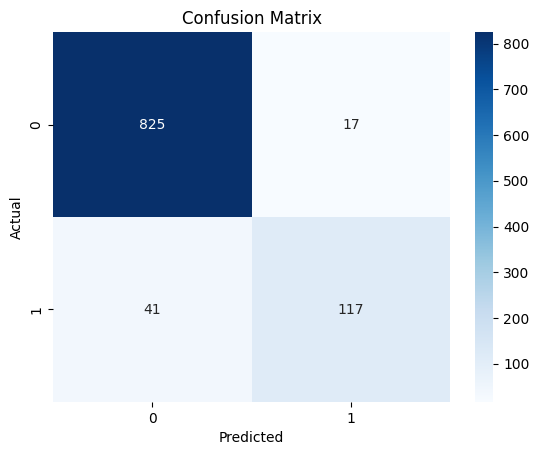

In [33]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Detailed report
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

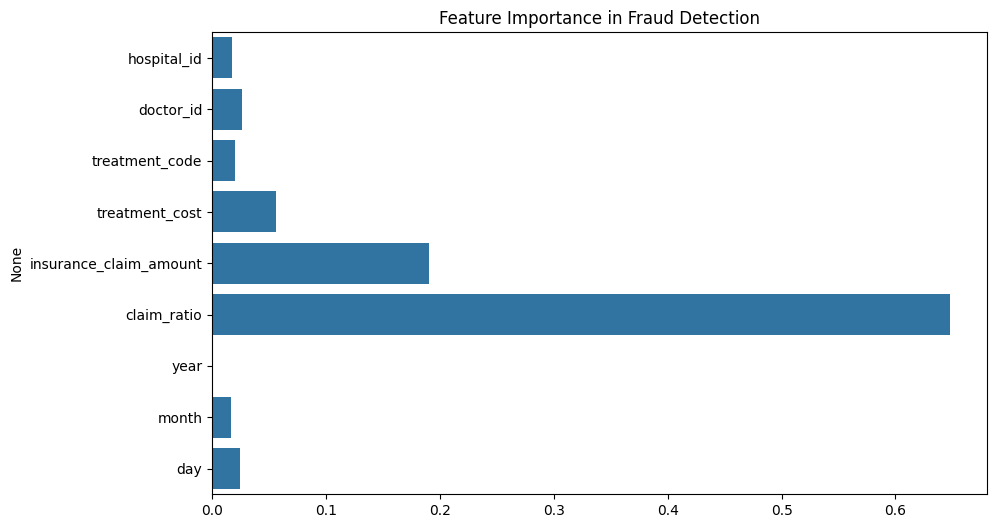

In [34]:
# Get feature importance
importances = model.feature_importances_
features = X.columns

# Plot
plt.figure(figsize=(10,6))
sns.barplot(x=importances, y=features)
plt.title("Feature Importance in Fraud Detection")
plt.show()